### Outlier Analysis strictly on Development Partition

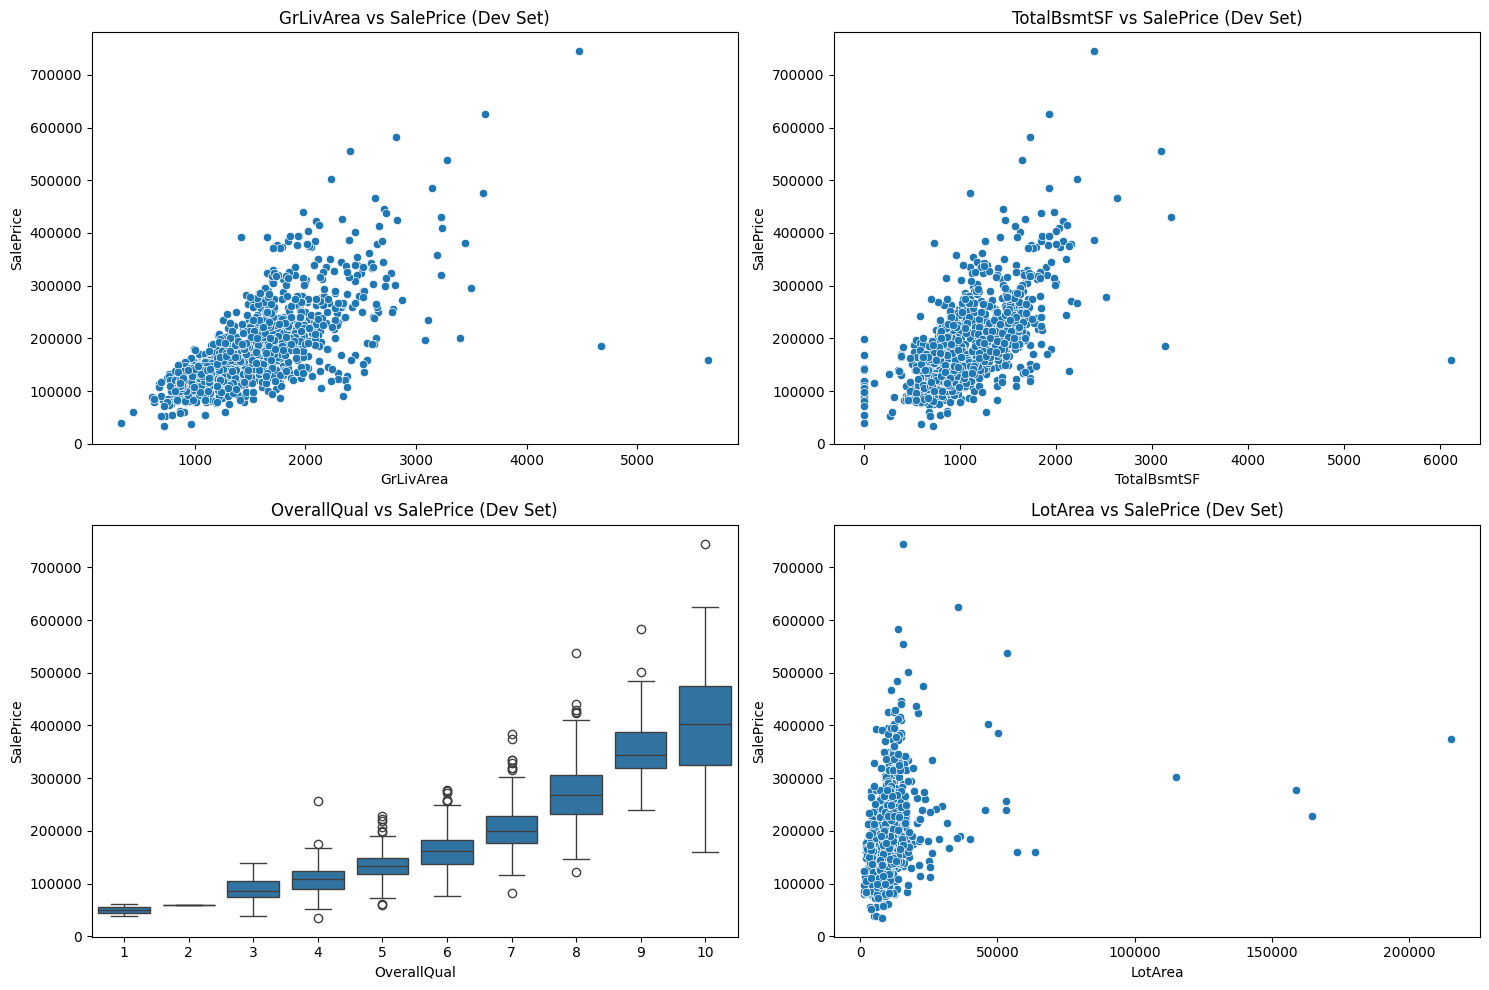

In [8]:
dev_plot_df = X_dev.copy()
dev_plot_df['SalePrice'] = y_dev

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 10))

sns.scatterplot(data=dev_plot_df, x='GrLivArea', y='SalePrice', ax=axes[0,0])
axes[0,0].set_title('GrLivArea vs SalePrice (Dev Set)')

sns.scatterplot(data=dev_plot_df, x='TotalBsmtSF', y='SalePrice', ax=axes[0,1])
axes[0,1].set_title('TotalBsmtSF vs SalePrice (Dev Set)')

sns.boxplot(x='OverallQual', y='SalePrice', data=dev_plot_df, ax=axes[1,0])
axes[1,0].set_title('OverallQual vs SalePrice (Dev Set)')

sns.scatterplot(data=dev_plot_df, x='LotArea', y='SalePrice', ax=axes[1,1])
axes[1,1].set_title('LotArea vs SalePrice (Dev Set)')

plt.tight_layout()
plt.show()

### Statistical Analysis of Outliers and Extreme Values

An extreme value in a feature space is not automatically a corrupt data point or candidate for deletion. In regression models, extreme values often represent genuine, high-value luxury properties rather than experimental errors. All observations will be kept within our development split unless an absolute data entry error is verified to avoid selection bias.

### Systematic Outlier Detection (All Development Numerical Features)

In [9]:
numeric_cols_dev = X_dev.select_dtypes(include=['int64', 'float64']).columns.tolist()
if 'MSSubClass' in numeric_cols_dev:
    numeric_cols_dev.remove('MSSubClass')

Q1 = X_dev[numeric_cols_dev].quantile(0.25)
Q3 = X_dev[numeric_cols_dev].quantile(0.75)
IQR = Q3 - Q1

outliers = ((X_dev[numeric_cols_dev] < (Q1 - 1.5 * IQR)) | (X_dev[numeric_cols_dev] > (Q3 + 1.5 * IQR)))
outlier_counts = outliers.sum().sort_values(ascending=False)

print("=== OUTLIER COUNTS PER NUMERICAL COLUMN (X_dev Only) ===")
display(outlier_counts[outlier_counts > 0].head(15))

=== OUTLIER COUNTS PER NUMERICAL COLUMN (X_dev Only) ===


,0
EnclosedPorch,160
BsmtFinSF2,131
OverallCond,99
ScreenPorch,97
MasVnrArea,77
LotFrontage,68
BsmtHalfBath,66
OpenPorchSF,60
KitchenAbvGr,56
LotArea,54


### Building the Authoritative Preprocessing ColumnTransformer

In [11]:
X_dev_engineered = HouseFeatureEngineer().transform(X_dev)

numerical_cols = [c for c in X_dev_engineered.columns if X_dev_engineered[c].dtype in ['int64', 'float64'] and c != 'MSSubClass']
categorical_cols = [c for c in X_dev_engineered.columns if X_dev_engineered[c].dtype == 'object'] + ['MSSubClass']

actual_na_cols = [c for c in na_meaningful_cols if c in categorical_cols]
actual_standard_cat_cols = [c for c in categorical_cols if c not in na_meaningful_cols]

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
    ('scaler', RobustScaler())
])

categorical_transformer_standard = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

categorical_transformer_na_valid = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='None')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_cols),
    ('cat_std', categorical_transformer_standard, actual_standard_cat_cols),
    ('cat_na', categorical_transformer_na_valid, actual_na_cols)
])

print("Authoritative Preprocessing ColumnTransformer successfully configured.")

Authoritative Preprocessing ColumnTransformer successfully configured.


## 11. Development Preprocessing Validation Check

In [23]:
fitted_engineering = selected_dev_model.named_steps['engineering']
fitted_preprocessor = selected_dev_model.named_steps['preprocessor']

X_engineered = fitted_engineering.transform(X_dev)
X_transformed = fitted_preprocessor.transform(X_engineered)

total_nulls_after = pd.DataFrame(X_transformed).isnull().sum().sum()
assert total_nulls_after == 0
assert np.isfinite(X_transformed).all()

print(f"SUCCESS: Validated preprocessing on X_dev. All transformed feature values are complete and finite.")

SUCCESS: Validated preprocessing on X_dev. All transformed feature values are complete and finite.
